# Assignment on estimating causal effects

## 1. Data Generating Process
We chose a simple 3-node DAG model with binary treatment T and continuous outcome Y under a single confounder Z.<br>
**DAG: Z->T->Y<-Z**

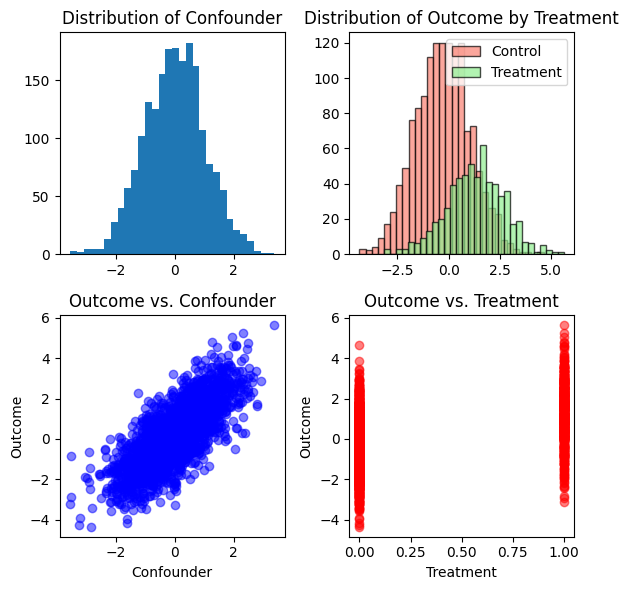

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# define some DEG params
te = 0.6789
n_samples = 2000

def gen_data():

    # Confounder
    confounder = np.random.normal(0, 1, n_samples)


    def treatment_probability(confounder):
        return 1 / (1 + np.exp(-(confounder - 1)))  # logistic function


    # Treatment
    treatment_prob = treatment_probability(confounder)
    treatment = np.random.binomial(1, treatment_prob, n_samples)

    # Outcome
    outcome_noise_mean = 0
    outcome_noise_std = 1
    outcome_noise = np.random.normal(outcome_noise_mean, outcome_noise_std, n_samples)
    outcome = (te * treatment) + confounder + outcome_noise

    data = pd.DataFrame(
        {
            "Treatment": treatment,
            "Outcome": outcome,
            "Confounder": confounder,
            "Outcome Noise": outcome_noise,
        }
    )

    return data


def visualize():
    """Visualization"""
    plt.figure(figsize=(6, 6))

    plt.subplot(2, 2, 1)
    plt.hist(data["Confounder"], bins=30)
    plt.title("Distribution of Confounder")

    plt.subplot(2, 2, 2)
    plt.hist(
        data[data["Treatment"] == 0]["Outcome"],
        bins=30,
        color="salmon",
        edgecolor="black",
        alpha=0.7,
        label="Control",
    )
    plt.hist(
        data[data["Treatment"] == 1]["Outcome"],
        bins=30,
        color="lightgreen",
        edgecolor="black",
        alpha=0.7,
        label="Treatment",
    )
    plt.title("Distribution of Outcome by Treatment")
    plt.legend()

    plt.subplot(2, 2, 3)
    plt.scatter(data["Confounder"], data["Outcome"], color="blue", alpha=0.5)
    plt.xlabel("Confounder")
    plt.ylabel("Outcome")
    plt.title("Outcome vs. Confounder")

    plt.subplot(2, 2, 4)
    plt.scatter(data["Treatment"], data["Outcome"], color="red", alpha=0.5)
    plt.xlabel("Treatment")
    plt.ylabel("Outcome")
    plt.title("Outcome vs. Treatment")

    plt.tight_layout()
    plt.show()

data = gen_data()
visualize()

## 2. Calculate ground truth ATE
Since the data generating process is known, we generate counterfactual outcomes under all interventions of interest. 

In [42]:
import math


def simulate_counterfactual_outcome(data, treatment_effect):
    # Simulate counterfactual outcomes
    data["Counterfactual_Y_1"] = (
        (treatment_effect * 1) + data["Confounder"] + data["Outcome Noise"]
    )
    data["Counterfactual_Y_0"] = (
        (treatment_effect * 0) + data["Confounder"] + data["Outcome Noise"]
    )

    # Calculate the ATE for each sample
    data["ATE"] = data["Counterfactual_Y_1"] - data["Counterfactual_Y_0"]

    return data["ATE"].mean()


ground_truth_ATE = simulate_counterfactual_outcome(data, te)
print("Ground truth ATE:", ground_truth_ATE)
assert math.isclose(
    ground_truth_ATE, te
)  # Should be same as defined treatment effect in the DEG

Ground truth ATE: 0.6789000000000001


The following code shows the ATE estimated by a naive estimator that simply calculates the mean outcome of treatment vs control group. As we see, it is way off.

In [43]:
# Calculate average outcome for the treated group
treated_outcome_mean = data[data["Treatment"] == 1]["Outcome"].mean()

# Calculate average outcome for the control group
control_outcome_mean = data[data["Treatment"] == 0]["Outcome"].mean()

# Calculate the ground truth ATE
ground_truth_ate = treated_outcome_mean - control_outcome_mean
print("Naive Estimator ATE:", ground_truth_ate)

Naive Estimator ATE: 1.5803396288510292


## Method 1: Inverse Propability of Treatment Weighting (IPTW)

Mean error: 0.060006780836787336
Standard deviation: 0.04211973406259174


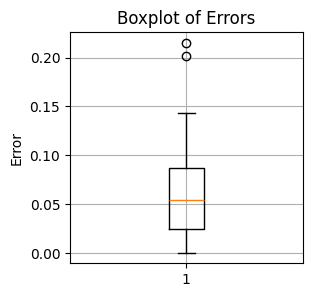

In [44]:
from sklearn.linear_model import LogisticRegression, LinearRegression

def iptw(data, show=True):
    treatment = data["Treatment"].values
    confounder = data["Confounder"].values

    propensity_model = LogisticRegression(C=1e6)
    propensity_model.fit(confounder.reshape(-1, 1), treatment)
    data["Propensity Scores"] = propensity_model.predict_proba(confounder.reshape(-1, 1))[
        :, 1
    ]

    ipw = np.where(
        treatment == 1,
        1 / data["Propensity Scores"].values,
        1 / (1 - data["Propensity Scores"].values),
    )
    weighted_outcomes = data["Outcome"] * ipw

    y_t = np.sum(weighted_outcomes[treatment == 1]) / len(treatment)
    y_u = np.sum(weighted_outcomes[treatment == 0]) / len(treatment)

    ATE = y_t - y_u
    if show:
        print("IPTW ATE", ATE)
    return ATE


def eval(method):
    def calc_err(pred):
        errors = np.abs(np.array(pred) - te)

        # Calculate mean error and standard deviation
        mean_error = np.mean(errors)
        std_dev = np.std(errors)

        print("Mean error:", mean_error)
        print("Standard deviation:", std_dev)

        # Plot boxplot of errors
        plt.figure(figsize=(3, 3))
        plt.boxplot(errors)
        plt.title('Boxplot of Errors')
        plt.ylabel('Error')
        plt.grid(True)
        plt.show()


    preds = []
    for _ in range(100):
        data=gen_data()
        preds.append(method(data, show=False))
    calc_err(preds)

eval(iptw)


## Method 2: Augmented Inverse Probability of Treatment Weighting (AIPTW)

Mean error: 0.045383922354361915
Standard deviation: 0.03509870547256547


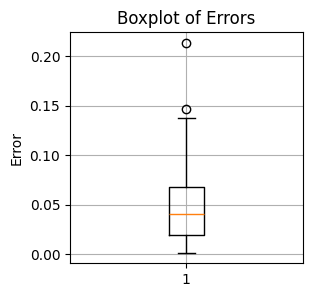

In [45]:
def aiptw(data, show=True):
    iptw(data, show=False)
    X = data[["Treatment", "Confounder"]]
    y = data["Outcome"]
    outcome_model = LinearRegression().fit(X, y)

    mtx = np.zeros((n_samples, 2))
    # mtx[:, 0] = 1
    mtx[:, -1] = data["Confounder"]

    mtx_2 = np.ones((n_samples, 2))
    mtx_2[:, -1] = data["Confounder"]

    mu0 = np.dot(mtx, outcome_model.coef_.T)
    mu1 = np.dot(mtx_2, outcome_model.coef_.T)

    w0 = (1 - data["Treatment"]) / (1 - data["Propensity Scores"])
    w1 = data["Treatment"] / data["Propensity Scores"]

    W0 = w0 / sum(w0)
    W1 = w1 / sum(w1)

    tilda = (
        np.mean(w1 * (data["Outcome"] - mu1))
        + np.mean(mu1)
        - np.mean(w0 * (data["Outcome"] - mu0))
        - np.mean(mu0)
    )
    hat = (
        np.sum(W1 * (data["Outcome"] - mu1))
        + np.mean(mu1)
        - np.sum(W0 * (data["Outcome"] - mu0))
        - np.mean(mu0)
    )
    avg_ate = (hat + tilda) / 2
    if show:
        print("Hat ATE:", hat)
        print("Tilda ATE:", tilda)
        print("AIPTW ATE (avg hat, tilda)", avg_ate)
    return avg_ate

eval(aiptw)

## Method 3: Double Machine Learning

Mean error: 0.0382968464777453
Standard deviation: 0.02916093962299867


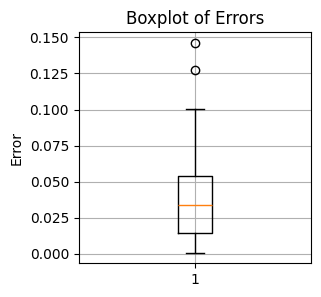

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

def double_ml(data, show=True):
    treatment = data["Treatment"].values
    covariate = data["Confounder"].values
    outcome = data["Outcome"].values

    # Split data for the purpose of cross-fitting
    X_main, X_aux, T_main, T_aux, Y_main, Y_aux = train_test_split(
        covariate, treatment, outcome, test_size=0.5, random_state=42
    )
    X_main = X_main.reshape(-1, 1)
    X_aux = X_aux.reshape(-1, 1)

    treatment_model_main = LinearRegression()
    outcome_model_aux = LinearRegression()
    treatment_model_main.fit(X_main, T_main)
    outcome_model_aux.fit(X_aux, Y_aux)
    Y_aux_pred = outcome_model_aux.predict(X_aux)
    T_main_pred = treatment_model_main.predict(X_main)


    treatment_model_aux = LinearRegression()
    outcome_model_main = LinearRegression()
    treatment_model_aux.fit(X_aux, T_aux)
    outcome_model_main.fit(X_main, Y_main)
    Y_main_pred = outcome_model_main.predict(X_main)
    T_aux_pred = treatment_model_aux.predict(X_aux)


    # compute residuals

    y_residuals_aux = Y_aux - Y_aux_pred
    t_residuals_main = T_main - T_main_pred

    y_residuals_main = Y_main - Y_main_pred
    t_residuals_aux = T_aux - T_aux_pred
    n = y_residuals_aux.shape[0]

    ATE_aux = (1 / ((1 / n) * np.dot(t_residuals_aux, T_aux))) * (
        (1 / n) * np.dot(t_residuals_aux, y_residuals_aux)
    )
    ATE_main = (1 / ((1 / n) * np.dot(t_residuals_main, T_main))) * (
        (1 / n) * np.dot(t_residuals_main, y_residuals_main)
    )
    ATE = (ATE_aux + ATE_main) / 2
    if show:
        print("double machine learning ATE:", ATE)
    return ATE
eval(double_ml)